<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Name      100 non-null    str  
 1   Currency  100 non-null    str  
 2   Borders   100 non-null    str  
 3   Area      100 non-null    int64
dtypes: int64(1), str(3)
memory usage: 3.3 KB
None


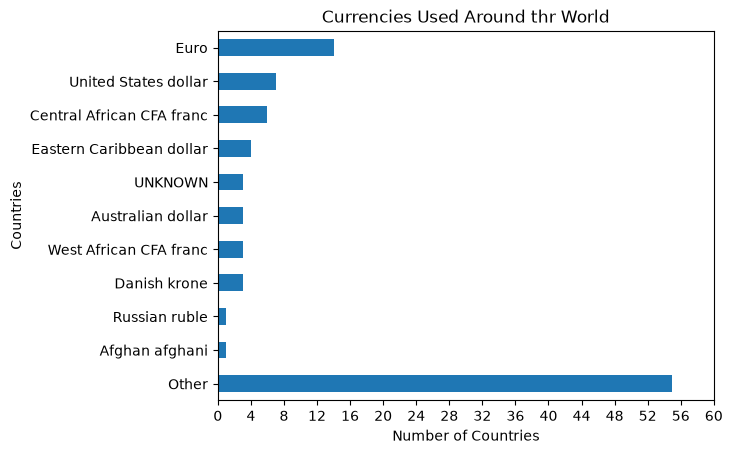

In [ ]:
# Taha Workspace
import pandas as pd
import sqlite3
import requests
import numpy as np
import matplotlib.pyplot as plt

API_key = 'https://api.restcountries.com/countries/v5?response_fields=names.common,borders,currencies,area&limit=100'

headers = {
    "Authorization": f"Bearer rc_live_c3badbed198e4610b8cc7f0abc9f7401"
}

response = requests.get(API_key, headers=headers)
if response.status_code == 200:
    data = response.json()
else:
    print(f"Error: {response.status_code} - {response.text}")
    

df = pd.DataFrame(data['data']['objects'])  

# Sitting names ---> Common name only
df['Name'] = df['names'].str['common'].astype(str)

# Sitting Currency ---> The first one in the list of used currencies
df['Currency'] = df['currencies'].str[0].str['name'].astype(str)

# sitting Area ---> Kilometers only
df['Area'] = df['area'].str['kilometers'].astype(int)

# Sitting Borders ---> Destructing the list
df['Borders'] = df['borders'].str.join(', ').astype(str) # Turn the list into Comma Separated Values (as one string)
df['Borders'] = df['Borders'].replace('', 'ISLAND') # Any empty string indicates an ISLAND

# Dropping old columns, keeping the new formatted
df = df[['Name', 'Currency', 'Borders','Area']]

# Dealing with null values in currencies
df['Currency'] = df['Currency'].fillna("UNKNOWN")

print(df.info())

#---------Charts-----------

# 1. Currencies Bubble Chart
currencies = df['Currency'].value_counts()[:10]

other_currencies = len(df['Currency'].value_counts())-10

currencies["Other"] = other_currencies

currencies.plot(kind='barh', x=range(0,60,2))

plt.gca().invert_yaxis()
plt.xticks(range(0,61,4))
# Add titles and labels
plt.title("Currencies Used Around thr World")
plt.xlabel("Number of Countries")
plt.ylabel("Countries")

# Display the plot
plt.show()


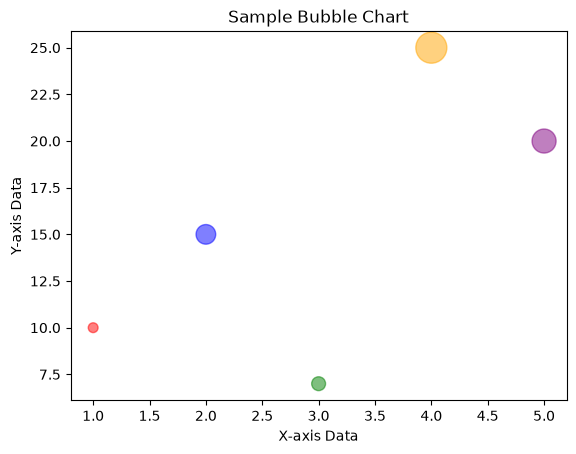

In [25]:
import matplotlib.pyplot as plt

# Data for the x and y axes
x = [1, 2, 3, 4, 5]
y = [10, 15, 7, 25, 20]

# Data for the bubble sizes (multiplied for visibility)
sizes = [50, 200, 100, 500, 300]

# Optional: Data for bubble colors
colors = ['red', 'blue', 'green', 'orange', 'purple']

# Create the scatter plot with the 's' parameter for sizes
plt.scatter(x, y, s=sizes, c=colors, alpha=0.5)

# Add titles and labels
plt.title("Sample Bubble Chart")
plt.xlabel("X-axis Data")
plt.ylabel("Y-axis Data")

# Display the plot
plt.show()

In [8]:
# Rawad Workspace
import pandas as pd
import sqlite3
import requests
import numpy

API_key = 'https://api.restcountries.com/countries/v5?response_fields=population,subregion,languages&limit=100'

headers = {
    "Authorization": f"Bearer rc_live_c3badbed198e4610b8cc7f0abc9f7401"
}

response = requests.get(API_key, headers=headers)
if response.status_code == 200:
    data = response.json()
else:
    print(f"Error: {response.status_code} - {response.text}")
    

df = pd.DataFrame(data['data']['objects'])  
df

,subregion,languages,population,_meta
0,Western Asia,"[{'bcp47': 'ab', 'iso639_1': 'ab', 'iso639_2b'...",244236,{'lastUpdatedTimestamp': 1788557516}
1,Southern Asia,"[{'bcp47': 'prs', 'iso639_1': '', 'iso639_2b':...",43844000,{'lastUpdatedTimestamp': 1788724017}
2,Southeast Europe,"[{'bcp47': 'sq', 'iso639_1': 'sq', 'iso639_2b'...",2335930,{'lastUpdatedTimestamp': 1788557516}
3,Northern Africa,"[{'bcp47': 'ar', 'iso639_1': 'ar', 'iso639_2b'...",47400000,{'lastUpdatedTimestamp': 1788557516}
4,Polynesia,"[{'bcp47': 'en', 'iso639_1': 'en', 'iso639_2b'...",43268,{'lastUpdatedTimestamp': 1788724017}
...,...,...,...,...
95,South America,"[{'bcp47': 'en', 'iso639_1': 'en', 'iso639_2b'...",956044,{'lastUpdatedTimestamp': 1792354394}
96,Caribbean,"[{'bcp47': 'fr', 'iso639_1': 'fr', 'iso639_2b'...",11867032,{'lastUpdatedTimestamp': 1788557518}
97,,"[{'bcp47': 'en', 'iso639_1': 'en', 'iso639_2b'...",0,{'lastUpdatedTimestamp': 1788724018}
98,Central America,"[{'bcp47': 'es', 'iso639_1': 'es', 'iso639_2b'...",10186738,{'lastUpdatedTimestamp': 1788557518}


In [ ]:
# Mohammad Workspace
import pandas as pd
import sqlite3
import requests
import numpy

API_key = 'https://api.restcountries.com/countries/v5?response_fields=economy,area,coordinates&limit=100'

headers = {
    "Authorization": f"Bearer rc_live_c3badbed198e4610b8cc7f0abc9f7401"
}

response = requests.get(API_key, headers=headers)
if response.status_code == 200:
    data = response.json()
else:
    print(f"Error: {response.status_code} - {response.text}")
    

df = pd.DataFrame(data['data']['objects'])  
df

,area,coordinates,economy,_meta
0,"{'kilometers': 8665, 'miles': 3345.6}","{'lat': 43, 'lng': 41}",{'gini_coefficient': {}},{'lastUpdatedTimestamp': 1788557516}
1,"{'kilometers': 652230, 'miles': 251827.3}","{'lat': 33, 'lng': 65}",{'gini_coefficient': {}},{'lastUpdatedTimestamp': 1788724017}
2,"{'kilometers': 28748, 'miles': 11099.7}","{'lat': 41, 'lng': 20}","{'gini_coefficient': {'2016': 33.7, '2017': 33...",{'lastUpdatedTimestamp': 1788557516}
3,"{'kilometers': 2381741, 'miles': 919595}","{'lat': 28, 'lng': 3}","{'gini_coefficient': {'1988': 37.4, '1995': 35...",{'lastUpdatedTimestamp': 1788557516}
4,"{'kilometers': 199, 'miles': 76.8}","{'lat': -14.33333333, 'lng': -170}",{'gini_coefficient': {}},{'lastUpdatedTimestamp': 1788724017}
...,...,...,...,...
95,"{'kilometers': 214969, 'miles': 83000}","{'lat': 5, 'lng': -59}","{'gini_coefficient': {'1992': 39.5, '1998': 45...",{'lastUpdatedTimestamp': 1792354394}
96,"{'kilometers': 27750, 'miles': 10714.3}","{'lat': 19, 'lng': -72.41666666}","{'gini_coefficient': {'2001': 59, '2012': 41.1}}",{'lastUpdatedTimestamp': 1788557518}
97,"{'kilometers': 412, 'miles': 159.1}","{'lat': -53.0818, 'lng': 73.5042}",{'gini_coefficient': {}},{'lastUpdatedTimestamp': 1788724018}
98,"{'kilometers': 112492, 'miles': 43433.4}","{'lat': 15, 'lng': -86.5}","{'gini_coefficient': {'2017': 49.4, '2018': 48...",{'lastUpdatedTimestamp': 1788557518}
